# 02e · Circuits vs the full model on the whole dataset

**Question:** if a circuit has to answer **on its own**, how close is it to the full model, prompt by prompt?

Models compared on all 690 prompts (P, S, N; discovery and held-out):
| model | edges |
|---|---|
| full model | all 23,577 |
| EAP-IG candidate (Phase 1b) | 9600 |
| ACDC v1 (8 + 8 pairs, edge by edge) | 726 |
| ACDC v3b, τ = 0 | 7078 |
| ACDC v3b, τ = 0.005 | ≈ 5100 |
| baselines: no edges (the average prompt), random edges (size of v3b τ = 0) | |

**How a circuit answers alone: edge-level mean ablation.** The faithfulness of Phases 1b–2 needs a corrupted partner
for every prompt. Here the edges **not** in the circuit get the **dataset mean** instead:
receiver input = mean input + Σ over circuit edges (output(prompt) − mean output). Means are taken position by
position over the prompts with the same number of tokens (they share the chat template). All edges → exactly
the full model; no edges → the same answer for every prompt of a length.

**Caveat.** The circuits were found to explain the *difference* S vs P/N under patching from a corrupted
partner, not the absolute answer under mean ablation, so this is a harder, different test. The
threshold-free measures (triple accuracy, correlation with the full model) are the fairest.

**Measures** (per split; held-out = the new phrase "Great, just what I needed."):
* **Yes rate** per condition (d > 0): S should be Yes, P and N No;
* **accuracy** against the labels, and **triple accuracy**: d(S) > d(P) and d(S) > d(N);
* **agreement** with the full model's answer, and the **correlation** of d with the full model's d.

**Settings:** `DATA` = which prompts (v1 pilot or v2), `CIRCUITS_FROM` = on which data the circuits were found.
With `DATA = "v2"` and `CIRCUITS_FROM = "v1"` this tests whether the v1 circuits generalise to new phrases and
sentence frames.

**Runtime:** any GPU with the 7B in 4-bit; v1 about 15 minutes, v2 (2730 prompts) about 40 minutes.

## Setup

In [1]:
# Get (or update) the code from GitHub
import os, sys
REPO = "https://github.com/vasilis-pantzos/sarcasm-proposal.git"
ROOT = "/content/sarcasm-proposal"
if not os.path.exists(ROOT):
    !git clone -q {REPO} {ROOT}
else:
    !git -C {ROOT} pull -q
os.chdir(ROOT)
sys.path.insert(0, ROOT)
%pip install -q -U accelerate bitsandbytes

In [2]:
import os, json, time, numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
from IPython.display import display
from src.model import load_model, model_info, DEV_MODEL, MAIN_MODEL
from src.prompts import load_dataset, encode, chat_text, make_pairs, data_tag
from src.patching import score_pairs, keep_correct
from src.acdc import faithfulness_many
from src.eap import build_graph, random_mask
from src.standalone import MeanReference, StandaloneEvaluator, standalone_d
from src.metric import triple_accuracy
from src.utils import mount_drive, results_dir, cached, set_seed

# ---------------- settings ----------------
MODEL = MAIN_MODEL          # DEV_MODEL (3B) for quick tests
DATA = "v2"                 # the prompts to test on: "v1" (pilot) or "v2" (data/make_dataset_v2.py)
CIRCUITS_FROM = "v2"        # the circuits: found on "v1" or on "v2" data
N_PAIRS_F = 32              # pairs per experiment and group for the faithfulness with corrupted partners
# ------------------------------------------
TAG_MODEL = MODEL.split("/")[-1]
TAG_C = TAG_MODEL + data_tag(CIRCUITS_FROM)        # where the circuits are
SUB = f"02e_compare_circuits/{TAG_MODEL}" + ("" if DATA == CIRCUITS_FROM == "v1" else f"_circuits-{CIRCUITS_FROM}_data-{DATA}")
mount_drive()
print("results go to:", results_dir(SUB))
set_seed(0)

Mounted at /content/drive
results go to: /content/drive/MyDrive/sarcasm/02e_compare_circuits/Qwen2.5-7B-Instruct_circuits-v2_data-v2


In [3]:
t0 = time.time()
model, tok = load_model(MODEL)
G = build_graph(model)
print(MODEL, model_info(model), f"loaded in {(time.time() - t0) / 60:.1f} min")

# the circuits (saved by notebooks 01b, 02 and 02d)
paths = {
    "EAP-IG candidate": f"01b_eap_ig/{TAG_C}/candidate_mask.npy",
    "ACDC v1": f"02_acdc/{TAG_C}/circuit_mask.npy",
    "ACDC v3b τ=0": f"02_acdc/{TAG_C}/v3b/acdc_mask_tau0.0.npy",
    "ACDC v3b τ=0.005": f"02_acdc/{TAG_C}/v3b/acdc_mask_tau0.005.npy",
}
CIRCUITS = {}
for name, p in paths.items():
    full = os.path.join(results_dir(""), p)
    if os.path.exists(full):
        CIRCUITS[name] = np.load(full)
    else:
        print("not found, skipped:", full)
size_ref = int(CIRCUITS.get("ACDC v3b τ=0", next(iter(CIRCUITS.values()))).sum())
CIRCUITS["random (same size as v3b τ=0)"] = random_mask(G, size_ref, np.random.default_rng(0))
CIRCUITS["no edges (average prompt)"] = np.zeros_like(G.valid)
for name, m in CIRCUITS.items():
    print(f"{name:34s} {int(m.sum()):6d} edges ({m.sum() / G.n_edges():.1%} of the graph)")

config.json:   0%|          | 0.00/663 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/27.8k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/339 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/243 [00:00<?, ?B/s]

Qwen/Qwen2.5-7B-Instruct {'n_layers': 28, 'n_heads': 28, 'n_kv_heads': 4, 'd_model': 3584, 'head_dim': 128} loaded in 1.2 min
not found, skipped: /content/drive/MyDrive/sarcasm/02_acdc/Qwen2.5-7B-Instruct_data-v2/circuit_mask.npy
EAP-IG candidate                     9600 edges (40.7% of the graph)
ACDC v3b τ=0                         8147 edges (34.6% of the graph)
ACDC v3b τ=0.005                     5722 edges (24.3% of the graph)
random (same size as v3b τ=0)        8147 edges (34.6% of the graph)
no edges (average prompt)               0 edges (0.0% of the graph)


## Data and the mean reference

In [4]:
df = load_dataset(DATA).sort_values(["split", "triple_id", "condition"]).reset_index(drop=True)
# groups: discovery, held-out with a new phrase, held-out with a new sentence frame (v2 only)
df["group"] = [s if s == "discovery" else f"heldout ({t})" for s, t in zip(df.split, df.heldout_type)]
GROUPS = [g for g in ["discovery", "heldout (phrase)", "heldout (frame)"] if g in set(df.group)]
print("prompts per group:", df.group.value_counts().to_dict())
encs = [encode(tok, r) for r in df.itertuples()]
IDS = [e.ids for e in encs]
PREFIX = int(np.median([e.regions["situation"][0] for e in encs]))
SUFFIX = int(np.median([len(e.ids) - (e.regions["phrase"][-1] + 1) for e in encs]))
df["n_tok"] = [len(x) for x in IDS]
print(f"{len(df)} prompts; lengths {df.n_tok.min()}–{df.n_tok.max()}; template prefix {PREFIX}, suffix {SUFFIX} tokens")

t0 = time.time()
REF = MeanReference(model, IDS, G, prefix=PREFIX, suffix=SUFFIX)
print("mean reference per length (prompts):", REF.counts, f"| {time.time() - t0:.0f} s")

prompts per group: {'discovery': 1890, 'heldout (phrase)': 630, 'heldout (frame)': 210}
2730 prompts; lengths 56–67; template prefix 33, suffix 18 tokens
mean reference per length (prompts): {56: 3, 57: 81, 58: 285, 59: 465, 60: 582, 61: 414, 62: 438, 63: 246, 64: 135, 65: 60, 66: 18, 67: 3} | 63 s


## Sanity check

All edges must give exactly the full model; no edges gives one answer per length.

In [5]:
T0 = df.n_tok.mode()[0]
idx = list(df.index[df.n_tok == T0][:16])
ev = StandaloneEvaluator(model, tok, [IDS[i] for i in idx], REF, G)
gap_all = np.abs(ev.d(G.valid) - ev.d_clean).max()
d_none = ev.d(np.zeros_like(G.valid))
print(f"all edges: max |d - d_full| = {gap_all:.5f} | no edges: d from {d_none.min():+.3f} to {d_none.max():+.3f}")
assert gap_all < 1e-3, "sanity check failed: send the output to Claude"
del ev; torch.cuda.empty_cache()
print("PASS")

all edges: max |d - d_full| = 0.00000 | no edges: d from +0.522 to +0.522
PASS


## Run every model on every prompt

In [6]:
t0 = time.time()
key = "standalone_d_" + "_".join(f"{int(m.sum())}" for m in CIRCUITS.values())
D = cached(key, lambda: standalone_d(model, tok, IDS, CIRCUITS, REF, G), sub=SUB)
print(f"done in {(time.time() - t0) / 60:.1f} min")
MODELS = ["full", *CIRCUITS]
for k in MODELS:
    df[f"d {k}"] = D[k]

  length 56: 3 prompts (3/2730)
  length 57: 81 prompts (84/2730)
  length 58: 285 prompts (369/2730)
  length 59: 465 prompts (834/2730)
  length 60: 582 prompts (1416/2730)
  length 61: 414 prompts (1830/2730)
  length 62: 438 prompts (2268/2730)
  length 63: 246 prompts (2514/2730)
  length 64: 135 prompts (2649/2730)
  length 65: 60 prompts (2709/2730)
  length 66: 18 prompts (2727/2730)
  length 67: 3 prompts (2730/2730)
[saved]  /content/drive/MyDrive/sarcasm/02e_compare_circuits/Qwen2.5-7B-Instruct_circuits-v2_data-v2/standalone_d_9600_8147_5722_8147_0.pt
done in 12.8 min


## Results

In [7]:
def summary(sub):
    rows = []
    full_yes = sub["d full"] > 0
    for k in MODELS:
        d = sub[f"d {k}"]
        yes = d > 0
        piv = sub.pivot(index="triple_id", columns="condition", values=f"d {k}")
        rows.append({
            "model": k,
            "edges": G.n_edges() if k == "full" else int(CIRCUITS[k].sum()),
            "Yes rate P": yes[sub.condition == "P"].mean(),
            "Yes rate S": yes[sub.condition == "S"].mean(),
            "Yes rate N": yes[sub.condition == "N"].mean(),
            "accuracy": (yes == (sub.condition == "S")).mean(),
            "triple accuracy": triple_accuracy(piv.P, piv.S, piv.N),
            "agreement with full": (yes == full_yes).mean(),
            "corr. of d with full": np.corrcoef(d, sub["d full"])[0, 1] if d.std() > 0 else np.nan,
            "mean d (S) - mean d (P,N)": d[sub.condition == "S"].mean() - d[sub.condition != "S"].mean(),
        })
    return pd.DataFrame(rows).set_index("model")

TABLES = {g: summary(df[df.group == g]) for g in GROUPS}
for split, t in TABLES.items():
    print(f"\n===== {split} ({(df.group == split).sum()} prompts) =====")
    display(t.round(3))


===== discovery (1890 prompts) =====


,edges,Yes rate P,Yes rate S,Yes rate N,accuracy,triple accuracy,agreement with full,corr. of d with full,"mean d (S) - mean d (P,N)"
model,,,,,,,,,
full,23577,0.084,0.773,0.329,0.787,0.810,1.000,1.000,10.590
EAP-IG candidate,9600,0.137,0.705,0.363,0.735,0.789,0.880,0.898,8.278
ACDC v3b τ=0,8147,0.144,0.737,0.413,0.726,0.771,0.876,0.896,7.728
ACDC v3b τ=0.005,5722,0.132,0.733,0.446,0.719,0.724,0.852,0.843,6.452
random (same size as v3b τ=0),8147,0.241,0.241,0.240,0.587,0.297,0.616,0.219,-0.000
no edges (average prompt),0,0.657,0.657,0.657,0.448,0.000,0.532,0.223,0.000



===== heldout (phrase) (630 prompts) =====


,edges,Yes rate P,Yes rate S,Yes rate N,accuracy,triple accuracy,agreement with full,corr. of d with full,"mean d (S) - mean d (P,N)"
model,,,,,,,,,
full,23577,0.252,0.900,0.600,0.683,0.790,1.000,1.000,10.627
EAP-IG candidate,9600,0.371,0.871,0.586,0.638,0.881,0.892,0.887,8.553
ACDC v3b τ=0,8147,0.414,0.871,0.629,0.610,0.833,0.867,0.885,7.430
ACDC v3b τ=0.005,5722,0.410,0.933,0.714,0.603,0.752,0.848,0.867,6.053
random (same size as v3b τ=0),8147,0.462,0.462,0.462,0.513,0.214,0.560,0.208,-0.009
no edges (average prompt),0,0.714,0.714,0.714,0.429,0.000,0.597,0.204,0.000



===== heldout (frame) (210 prompts) =====


,edges,Yes rate P,Yes rate S,Yes rate N,accuracy,triple accuracy,agreement with full,corr. of d with full,"mean d (S) - mean d (P,N)"
model,,,,,,,,,
full,23577,0.129,0.843,0.300,0.805,0.843,1.000,1.000,11.199
EAP-IG candidate,9600,0.114,0.571,0.329,0.710,0.771,0.771,0.805,4.841
ACDC v3b τ=0,8147,0.057,0.571,0.400,0.705,0.671,0.776,0.800,4.005
ACDC v3b τ=0.005,5722,0.300,0.771,0.743,0.576,0.586,0.695,0.749,3.729
random (same size as v3b τ=0),8147,0.743,0.743,0.743,0.419,0.314,0.471,0.043,0.001
no edges (average prompt),0,0.971,0.971,0.971,0.343,0.014,0.433,0.059,0.000


### Yes rate per condition (the ideal: P 0 %, S 100 %, N 0 %)

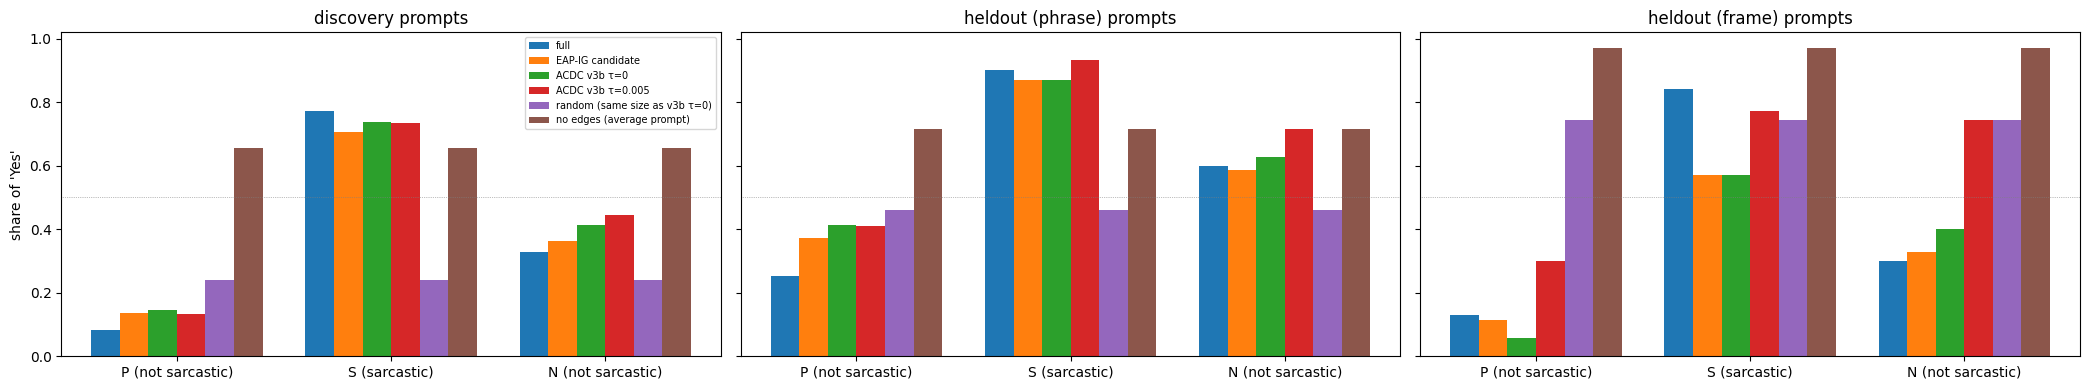

In [8]:
cols = plt.cm.tab10(np.arange(len(MODELS)))
fig, axes = plt.subplots(1, len(TABLES), figsize=(7 * len(TABLES), 4), sharey=True)
for ax, (split, t) in zip(np.atleast_1d(axes), TABLES.items()):
    w = 0.8 / len(MODELS)
    for i, k in enumerate(MODELS):
        ax.bar(np.arange(3) + (i - len(MODELS) / 2 + 0.5) * w, [t.loc[k, f"Yes rate {c}"] for c in "PSN"], w,
               color=cols[i], label=k)
    ax.set_xticks(range(3)); ax.set_xticklabels(["P (not sarcastic)", "S (sarcastic)", "N (not sarcastic)"])
    ax.set_title(f"{split} prompts"); ax.axhline(0.5, c="gray", lw=0.5, ls=":")
np.atleast_1d(axes)[0].set_ylabel("share of 'Yes'"); np.atleast_1d(axes)[0].legend(fontsize=7)
plt.tight_layout(); plt.savefig(os.path.join(results_dir(SUB), "yes_rate.png"), dpi=150); plt.show()

### Triple accuracy and agreement with the full model

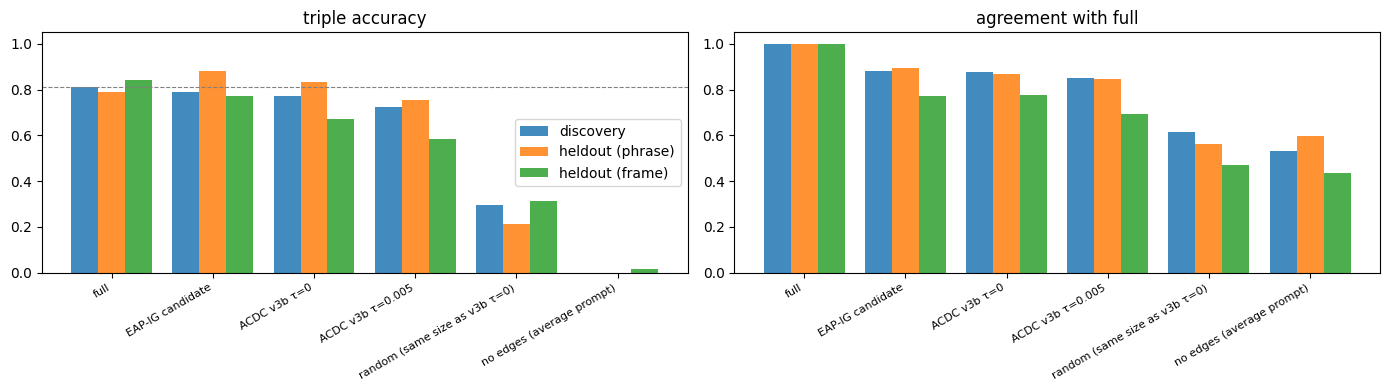

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, meas in zip(axes, ["triple accuracy", "agreement with full"]):
    x = np.arange(len(MODELS))
    w = 0.8 / len(TABLES)
    for j, split in enumerate(TABLES):
        ax.bar(x + (j - (len(TABLES) - 1) / 2) * w, TABLES[split][meas].values, w, label=split, alpha=0.85)
    ax.set_xticks(x); ax.set_xticklabels(MODELS, rotation=30, ha="right", fontsize=8)
    ax.set_title(meas); ax.set_ylim(0, 1.05)
axes[0].axhline(TABLES["discovery"].loc["full", "triple accuracy"], c="gray", ls="--", lw=0.8)
axes[0].legend()
plt.tight_layout(); plt.savefig(os.path.join(results_dir(SUB), "triple_accuracy_agreement.png"), dpi=150); plt.show()

### d of each circuit vs d of the full model (every dot is a prompt)

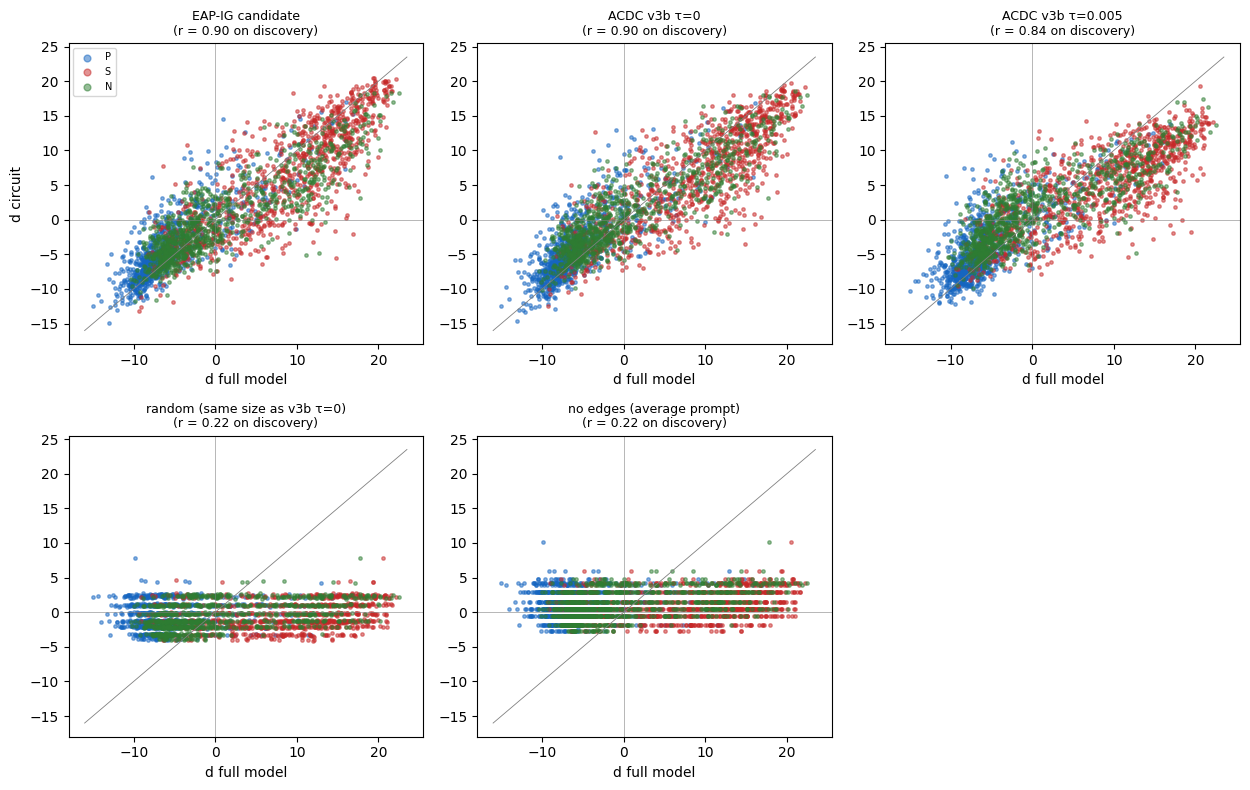

In [10]:
circ = [k for k in MODELS if k != "full"]
ccol = {"P": "#1565C0", "S": "#C62828", "N": "#2E7D32"}
fig, axes = plt.subplots(2, (len(circ) + 1) // 2, figsize=(4.2 * ((len(circ) + 1) // 2), 8))
for ax, k in zip(axes.flat, circ):
    for c in "PSN":
        s = df[df.condition == c]
        ax.scatter(s["d full"], s[f"d {k}"], s=6, alpha=0.5, color=ccol[c], label=c)
    lim = [df["d full"].min() - 1, df["d full"].max() + 1]
    ax.plot(lim, lim, c="gray", lw=0.6); ax.axhline(0, c="gray", lw=0.4); ax.axvline(0, c="gray", lw=0.4)
    r = TABLES["discovery"].loc[k, "corr. of d with full"]
    ax.set_title(f"{k}\n(r = {r:.2f} on discovery)", fontsize=9); ax.set_xlabel("d full model")
axes.flat[0].set_ylabel("d circuit"); axes.flat[0].legend(fontsize=7, markerscale=2)
for ax in list(axes.flat)[len(circ):]:
    ax.axis("off")
plt.tight_layout(); plt.savefig(os.path.join(results_dir(SUB), "d_vs_full.png"), dpi=150); plt.show()

### A few triples (held-out = the new phrase)

In [11]:
rng = np.random.default_rng(1)
show = []
for split in GROUPS:
    tids = rng.choice(df[df.group == split].triple_id.unique(), 3, replace=False)
    show.append(df[df.triple_id.isin(tids)])
cols_show = ["group", "triple_id", "condition", "text"] + [f"d {k}" for k in MODELS]
display(pd.concat(show)[cols_show].round(2))

,group,triple_id,condition,text,d full,d EAP-IG candidate,d ACDC v3b τ=0,d ACDC v3b τ=0.005,d random (same size as v3b τ=0),d no edges (average prompt)
891,discovery,429,N,First thing this morning: stale bread. What a ...,-4.34,-2.05,-1.85,-1.40,-2.13,-0.60
892,discovery,429,P,First thing this morning: fresh bread. What a ...,-9.70,-9.56,-7.67,-7.96,-2.02,-0.60
893,discovery,429,S,First thing this morning: stale bread. What a ...,3.94,14.06,11.83,7.48,-2.10,-0.60
963,discovery,461,N,My weekend was all about a spoiled lunch. The ...,-1.83,-1.06,-2.70,0.32,0.86,2.92
964,discovery,461,P,My weekend was all about a free lunch. My favo...,-4.60,-6.34,-6.97,-5.10,1.02,2.92
965,discovery,461,S,My weekend was all about a spoiled lunch. My f...,-3.39,-5.69,-5.67,-5.09,1.09,2.92
1425,discovery,683,N,Today was all about a cracked phone. Absolutel...,-6.33,-5.93,-5.39,-5.07,-3.96,-2.77
1426,discovery,683,P,Today was all about a new phone. Absolutely fa...,-7.13,-5.38,-6.49,-6.23,-3.93,-2.77
1427,discovery,683,S,Today was all about a cracked phone. Absolutel...,-3.39,-1.35,-0.54,-2.25,-4.02,-2.77
2004,heldout (phrase),128,N,My weekend was all about a slow internet conne...,2.01,-4.92,-3.36,2.27,-1.31,0.52


## Faithfulness alone, and calibrated accuracy

*Faithfulness alone*: (d_circuit − d_no edges) / (d_full − d_no edges) per prompt (1 = like the full model,
0 = like the average prompt); one number per group (slope through the origin) and the typical prompt (median over
prompts where the full model moves by more than 1). *Calibrated accuracy*: every model gets its own Yes/No
threshold, chosen on discovery (maximum balanced accuracy, S = Yes), then applied unchanged to the held-out groups.

In [12]:
NONE = "no edges (average prompt)"
rows = []
for gname in GROUPS:
    sub = df[df.group == gname]
    base, full = sub[f"d {NONE}"].values, sub["d full"].values
    den = full - base
    for k in MODELS:
        if k in ("full", NONE):
            continue
        num = sub[f"d {k}"].values - base
        ok = np.abs(den) > 1
        rows.append(dict(model=k, group=gname, slope=(num * den).sum() / (den ** 2).sum(),
                         median=np.median(num[ok] / den[ok])))
FA = pd.DataFrame(rows).pivot(index="model", columns="group", values=["slope", "median"])
print("Faithfulness of each circuit ALONE (1 = full model, 0 = no edges)")
display(FA.round(3))

def bal_acc(yes, y):
    return 0.5 * (yes[y].mean() + (~yes[~y]).mean())

disc = df[df.group == "discovery"]
y_d = (disc.condition == "S").values
rows = []
for k in MODELS:
    dd = disc[f"d {k}"].values
    s = np.sort(np.unique(dd))
    cands = np.concatenate([[s[0] - 1], (s[:-1] + s[1:]) / 2, [s[-1] + 1]])
    t = cands[int(np.argmax([bal_acc(dd > c, y_d) for c in cands]))]
    row = dict(model=k, threshold=t)
    for gname in GROUPS:
        sub = df[df.group == gname]
        y, dg = (sub.condition == "S").values, sub[f"d {k}"].values
        row[f"{gname} (d>0)"] = bal_acc(dg > 0, y)
        row[f"{gname} (own threshold)"] = bal_acc(dg > t, y)
    rows.append(row)
CAL = pd.DataFrame(rows).set_index("model")
print("\nBalanced accuracy (0.5 = chance), threshold 0 and each model's own threshold from discovery")
display(CAL.round(3))
FA.to_csv(os.path.join(results_dir(SUB), "faithfulness_alone.csv"))
CAL.to_csv(os.path.join(results_dir(SUB), "calibrated_accuracy.csv"))

Faithfulness of each circuit ALONE (1 = full model, 0 = no edges)


slope                                   \
group                         discovery heldout (frame) heldout (phrase)   
model                                                                      
ACDC v3b τ=0                      0.735           0.565            0.679   
ACDC v3b τ=0.005                  0.610           0.478            0.568   
EAP-IG candidate                  0.760           0.611            0.707   
random (same size as v3b τ=0)     0.014           0.054           -0.047   

                                 median                                   
group                         discovery heldout (frame) heldout (phrase)  
model                                                                     
ACDC v3b τ=0                      0.770           0.694            0.670  
ACDC v3b τ=0.005                  0.658           0.450            0.586  
EAP-IG candidate                  0.796           0.765            0.685  
random (same size as v3b τ=0)     0.188           0.205           -0.101


Balanced accuracy (0.5 = chance), threshold 0 and each model's own threshold from discovery


,threshold,discovery (d>0),discovery (own threshold),heldout (phrase) (d>0),heldout (phrase) (own threshold),heldout (frame) (d>0),heldout (frame) (own threshold)
model,,,,,,,
full,-0.619,0.783,0.787,0.737,0.740,0.814,0.789
EAP-IG candidate,-1.740,0.727,0.737,0.696,0.663,0.675,0.664
ACDC v3b τ=0,-0.560,0.729,0.733,0.675,0.670,0.671,0.664
ACDC v3b τ=0.005,-0.113,0.722,0.724,0.686,0.686,0.625,0.618
random (same size as v3b τ=0),0.969,0.500,0.509,0.500,0.510,0.500,0.514
no edges (average prompt),-3.767,0.500,0.500,0.500,0.500,0.500,0.500


## Faithfulness with corrupted partners (pairs), per group

The measure of Phases 1b–2: S with the edges outside the circuit taken from its partner (P for the situation
swap, N for the phrase swap); F = 1 like the full model, 0 like the partner. Up to `N_PAIRS_F` token-matched pairs
that the full model answers correctly, per experiment and group.

In [13]:
def pair_faith():
    out = {}
    masks = {k: m for k, m in CIRCUITS.items() if k != NONE}
    for gname in GROUPS:
        sub = df[df.group == gname]
        split = "discovery" if gname == "discovery" else "heldout"
        for e in ["situation", "phrase"]:
            ps = keep_correct(score_pairs(model, tok, make_pairs(sub, tok, e, split=split)))[:N_PAIRS_F]
            if ps:
                out[(gname, e)] = (len(ps), faithfulness_many(model, tok, ps, masks, G, batch=16))
    return out

PF = cached(f"pair_faithfulness_n{N_PAIRS_F}", pair_faith, sub=SUB)
rows = []
for (gname, e), (n, F) in PF.items():
    rows.append(dict(group=gname, experiment=e, pairs=n, **{k: float(np.mean(v)) for k, v in F.items()}))
if rows:
    PFT = pd.DataFrame(rows).set_index(["group", "experiment"])
    display(PFT.round(3))
    PFT.to_csv(os.path.join(results_dir(SUB), "pair_faithfulness.csv"))
else:
    print("no token-matched pairs that the full model answers correctly")

[saved]  /content/drive/MyDrive/sarcasm/02e_compare_circuits/Qwen2.5-7B-Instruct_circuits-v2_data-v2/pair_faithfulness_n32.pt


pairs  EAP-IG candidate  ACDC v3b τ=0  \
group            experiment                                          
discovery        situation      32             0.827         0.790   
                 phrase         32             1.244         1.219   
heldout (phrase) situation      32             0.879         0.778   
                 phrase         32             1.133         1.037   
heldout (frame)  situation      32             0.945         0.869   
                 phrase         32             0.984         0.939   

                             ACDC v3b τ=0.005  random (same size as v3b τ=0)  
group            experiment                                                   
discovery        situation              0.708                         -0.002  
                 phrase                 1.099                          0.006  
heldout (phrase) situation              0.695                          0.001  
                 phrase                 0.766                          0.003  
heldout (frame)  situation              0.873                         -0.000  
                 phrase                 0.762                          0.002

## Try your own sentence

Write a sentence; every model answers (d > 0 = Yes). P(Yes) = probability of Yes among {Yes, No}.

In [14]:
SENTENCE = "I spent the whole weekend fixing my car. What a fantastic way to relax."

template = df.prompt.iloc[0].replace(df.text.iloc[0], "{}")
ids = tok(chat_text(tok, template.format(SENTENCE)), add_special_tokens=False)["input_ids"]
ev = StandaloneEvaluator(model, tok, [ids], REF, G)
print(SENTENCE, f"\n({len(ids)} tokens" + ("" if ev.exact_mean else ", mean reference aligned from the closest length") + ")\n")
for k in MODELS:
    d = float(ev.d_clean[0]) if k == "full" else float(ev.d(CIRCUITS[k])[0])
    print(f"{k:34s} d = {d:+6.2f}  P(Yes) = {1 / (1 + np.exp(-d)):.2f}  -> {'Yes (sarcastic)' if d > 0 else 'No'}")
del ev; torch.cuda.empty_cache()

I spent the whole weekend fixing my car. What a fantastic way to relax. 
(62 tokens)

full                               d =  +1.84  P(Yes) = 0.86  -> Yes (sarcastic)
EAP-IG candidate                   d = +15.15  P(Yes) = 1.00  -> Yes (sarcastic)
ACDC v3b τ=0                       d = +13.38  P(Yes) = 1.00  -> Yes (sarcastic)
ACDC v3b τ=0.005                   d = +15.88  P(Yes) = 1.00  -> Yes (sarcastic)
random (same size as v3b τ=0)      d =  +1.14  P(Yes) = 0.76  -> Yes (sarcastic)
no edges (average prompt)          d =  +2.92  P(Yes) = 0.95  -> Yes (sarcastic)


## Save

In [15]:
d = results_dir(SUB)
df.drop(columns=["prompt"]).to_csv(os.path.join(d, "d_per_prompt.csv"), index=False)
for split, t in TABLES.items():
    t.to_csv(os.path.join(d, f"summary_{split.replace(' ', '_').replace('(', '').replace(')', '')}.csv"))
json.dump({split: t.round(4).reset_index().to_dict(orient="records") for split, t in TABLES.items()},
          open(os.path.join(d, "summary.json"), "w"), indent=1, ensure_ascii=False)
print("saved to", d)

saved to /content/drive/MyDrive/sarcasm/02e_compare_circuits/Qwen2.5-7B-Instruct_circuits-v2_data-v2


Edge overlap of the circuits found on v1 and on v2


,edges_v1,edges_v2,shared,jaccard,share_of_smaller,random_expected_shared,shared_vs_random
circuit,,,,,,,
EAP-IG candidate,9600,9600,7919,0.702,0.825,3909,2.026
ACDC v3b τ=0,7078,8147,5549,0.573,0.784,2446,2.269
ACDC v3b τ=0.005,5062,5722,3805,0.545,0.752,1229,3.097



Spearman correlation of the EAP-IG edge scores, v1 vs v2: 0.868
  top- 100 edges: 87 shared (87%; random: 0.4%)
  top- 500 edges: 397 shared (79%; random: 2.1%)
  top-2000 edges: 1569 shared (78%; random: 8.5%)


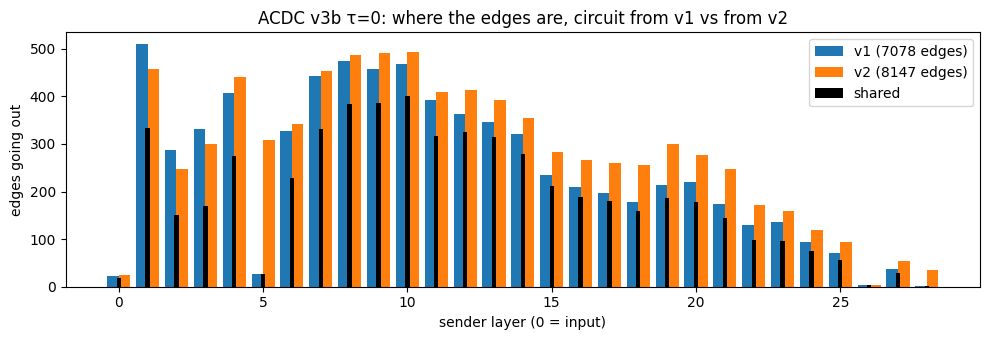

In [16]:
from scipy.stats import spearmanr
ROOT = "/content/drive/MyDrive/sarcasm"
M = "Qwen2.5-7B-Instruct"
L, H = 28, 28
# valid edges (as in src/eap.build_graph): sender order input=-1, heads of l = 2l, MLP l = 2l+1
s_ord = np.array([-1] + [2 * l for l in range(L) for _ in range(H)] + [2 * l + 1 for l in range(L)])
r_ord = np.array([2 * l for l in range(L)] + [2 * l + 1 for l in range(L)] + [2 * L])
VALID = s_ord[:, None] < r_ord[None, :]
NV = int(VALID.sum())

def load(p):
    p = os.path.join(ROOT, p)
    return np.load(p) if os.path.exists(p) else None

PATHS = {
    "EAP-IG candidate": "01b_eap_ig/{}/candidate_mask.npy",
    "ACDC v3b τ=0":     "02_acdc/{}/v3b/acdc_mask_tau0.0.npy",
    "ACDC v3b τ=0.005": "02_acdc/{}/v3b/acdc_mask_tau0.005.npy",
}
rows = []
for name, pat in PATHS.items():
    a, b = load(pat.format(M)), load(pat.format(M + "_data-v2"))
    if a is None or b is None:
        print("missing:", name); continue
    a, b = a & VALID, b & VALID
    na, nb, both = int(a.sum()), int(b.sum()), int((a & b).sum())
    exp = na * nb / NV                                    # expected overlap of two random circuits of these sizes
    rows.append(dict(circuit=name, edges_v1=na, edges_v2=nb, shared=both,
                     jaccard=both / (na + nb - both), share_of_smaller=both / min(na, nb),
                     random_expected_shared=round(exp), shared_vs_random=both / exp))
TAB = pd.DataFrame(rows).set_index("circuit")
print("Edge overlap of the circuits found on v1 and on v2")
display(TAB.round(3))

# the EAP-IG scores themselves: same ranking of edges?
s1 = np.load(os.path.join(ROOT, f"01b_eap_ig/{M}/mean_scores.npz"))["combined"][VALID]
s2 = np.load(os.path.join(ROOT, f"01b_eap_ig/{M}_data-v2/mean_scores.npz"))["combined"][VALID]
print(f"\nSpearman correlation of the EAP-IG edge scores, v1 vs v2: {spearmanr(np.abs(s1), np.abs(s2)).correlation:.3f}")
for k in [100, 500, 2000]:
    t1, t2 = set(np.argsort(-np.abs(s1))[:k]), set(np.argsort(-np.abs(s2))[:k])
    print(f"  top-{k:4d} edges: {len(t1 & t2)} shared ({len(t1 & t2) / k:.0%}; random: {k / NV:.1%})")

# where the edges are: count per sender layer, v1 vs v2 (ACDC v3b τ=0)
def per_layer(m):
    lay = np.array([0] + [1 + l for l in range(L) for _ in range(H)] + [1 + l for l in range(L)])
    return np.bincount(lay, weights=m.sum(1), minlength=L + 1)
a, b = load(f"02_acdc/{M}/v3b/acdc_mask_tau0.0.npy"), load(f"02_acdc/{M}_data-v2/v3b/acdc_mask_tau0.0.npy")
if a is not None and b is not None:
    fig, ax = plt.subplots(figsize=(10, 3.5))
    x = np.arange(L + 1)
    ax.bar(x - 0.2, per_layer(a & VALID), 0.4, label=f"v1 ({int((a & VALID).sum())} edges)")
    ax.bar(x + 0.2, per_layer(b & VALID), 0.4, label=f"v2 ({int((b & VALID).sum())} edges)")
    ax.bar(x, per_layer(a & b & VALID), 0.15, color="black", label="shared")
    ax.set_xlabel("sender layer (0 = input)"); ax.set_ylabel("edges going out")
    ax.set_title("ACDC v3b τ=0: where the edges are, circuit from v1 vs from v2"); ax.legend()
    plt.tight_layout(); plt.savefig(os.path.join(ROOT, "circuits_v1_vs_v2_per_layer.png"), dpi=150); plt.show()